## Load and prepare data 

Load and prepare data for backtrajectory calculations.

- Load the NSIDC PP data: `ds`

    - Loading a single, concatenated dataset from multiple source files.
    - Interpolating over a few holes in the data.
    
- Load a land mask: `MASK`
    - Define a land mask of land/no land that we use to kill trajectories that intersect a coastline.

In [38]:
import numpy as np
import xarray as xr
import glob
import pyproj
import matplotlib.pyplot as plt
from matplotlib.dates import date2num
import cmocean
import re

### Load data

Replace the *ddir* folder with the directory containing the PP NSIDC files (e.g. *icemotion_daily_nh_25km_20120101_20121231_v4.1.nc*)

In [13]:
ddir ='/media/oyvindl/ratatosk/data/sea_ice_drift/nsidc_polar_pathfinder/modern_subset/'
ddir ='/media/oyvindf/SKADI/sea_ice/sea_ice_drift/nsidc_polar_pathfinder_v4/source/annual_drift_vectors/'

flist = glob.glob(ddir + '*nc')

# It costs a little to load the whole thing

min_year = 2015
max_year = 2021

flist = [
    f for f in flist
    if min_year <= int(re.search(r'_(\d{4})\d{4}_', f).group(1)) < max_year
]

Lazy load of the data (concatenating the files) 

In [14]:
# Loading
# ("minimal" keyword avoids adding a time dimension to lat,lon)
try:
    ds = xr.open_mfdataset(flist, data_vars = 'minimal')
except:
    raise Exception('Failed to open files..\n(Looked for files here: %s)'%ddir)
# Last value is empty -> drop
ds = ds.drop_sel(time=ds.time.data[-1])

### Interpolate over NaN days

Some days, like 31.12 on 2020 and 2021, are all nans. 

-> Linearly interpolating between adjectent days (considering NaNs as zeros, 
but setting all-zero points to nan..)

In [15]:
# Indices where all values are NaN
isnan_all = np.isnan(ds.u.max(dim = ['x', 'y']))
is_nan_indices = np.where(isnan_all)[0]

In [16]:
# For each Nan index: Interpolate across from adjacent days

for nan_ind in is_nan_indices:
    u_nanind =  0.5*(ds.u[nan_ind-1].fillna(0) + ds.u[nan_ind+1].fillna(0))
    v_nanind =  0.5*(ds.v[nan_ind-1].fillna(0) + ds.v[nan_ind+1].fillna(0))
    
    u_nanind = u_nanind.where(np.bool_((u_nanind!=0) * (v_nanind!=0)))
    v_nanind = v_nanind.where(np.bool_((u_nanind!=0) * (v_nanind!=0)))

    ds.u[nan_ind] = u_nanind
    ds.v[nan_ind] = v_nanind

##### (Optional): Quick check

Toggle *check_interpolation=True* to show a quick check of the interpolation on Dec 31 2020..


In [17]:
check_interpolation = False

if check_interpolation:
    x_point, y_point = 180, 180
    
    fig, ax = plt.subplots(figsize = (11, 3))
    
    ax.plot_date(date2num(ds.time), ds.u.isel(x=x_point, y=y_point), '-k', alpha = 0.3)
    ax.plot_date(date2num(ds.time), ds.u.isel(x=x_point, y=y_point), '.', ms = 6, 
                 label = 'u (original)')
    ax.plot_date(ds.time[is_nan_indices[0]], 
                 ds.u.isel(x=x_point, y=y_point)[is_nan_indices[0]], '*y', ms = 12,
                 label = 'u (interpolated)')
    ax.plot_date(date2num(ds.time), ds.v.isel(x=x_point, y=y_point), '-k', alpha = 0.3)
    ax.plot_date(date2num(ds.time), ds.v.isel(x=x_point, y=y_point), '.', ms = 6, 
                 label = 'v (original)')
    ax.plot_date(ds.time[is_nan_indices[0]], 
                 ds.v.isel(x=x_point, y=y_point)[is_nan_indices[0]], '*r', ms = 12, 
                 label = 'v (interpolated)')

    for t_ in date2num(ds.time):
        ax.vlines(t_, -50, 50, 'k', alpha = 0.2)
    ax.set_xlim(18618, 18633)
    ax.set_ylim(-10, 10)
    ax.legend(ncol = 2, fontsize = 9)

### Define a land mask

Here, we can define a land mask (*MASK*) that will be used to kill a backtrajectory when it intersects a coastline.

*MASK* should have the following variables:
- *x, y* - Grid 
- *is_land* - Boolean (land=1, not land = 0)  
- *proj* - pyproj.CRS defining the grid projection of *x, y*


In my case, I am using a 2km land mask for the Eurasian sector based on IBCAO-v4, where I have removed Svalbard in order to allow trajectories to pass through islands. This mask was made elsewhere - I am just loading it here.

We can choose not to use a land mask. In that case, set *no_land_mask = True*

In [18]:
no_land_mask = False

In [20]:
# Load the land mask based on IBCAO (and defining the projection of this mask):
if not no_land_mask:
    my_mask_proj = pyproj.CRS('epsg:3996')  
    my_mask = xr.open_dataset(
        '/media/oyvindf/SKADI/geodata/bathymetry/ibcao_v4/netcdf/IBCAO_landmask_greater_barents_2km.nc')
    mask_is_land = my_mask.landmask_wo_svb
    # (Also adding lon/lat, but thise aren't strictly necessary)
    MASK = xr.Dataset(coords = {'x':my_mask.x, 'y':my_mask.y},
                     data_vars = {'lon':my_mask.lon, 'lat':my_mask.lat,
                                  'is_land':mask_is_land})
    MASK['proj'] = ((), my_mask_proj)

In [21]:
# If we dont have a land mask/dont want to use one:
if no_land_mask:
    MASK = None

##### (Optional): Quick check of mask

Toggle *show_mask=True* to show a quick landmask plot

In [35]:
ax.coastlines?

Signature: ax.coastlines(resolution='auto', color='black', **kwargs)
Docstring:
Add coastal **outlines** to the current axes from the Natural Earth
"coastline" shapefile collection.

Parameters
----------
resolution : str or :class:`cartopy.feature.Scaler`, optional
    A named resolution to use from the Natural Earth
    dataset. Currently can be one of "auto" (default), "110m", "50m",
    and "10m", or a Scaler object.  If "auto" is selected, the
    resolution is defined by `~cartopy.feature.auto_scaler`.
File:      ~/miniforge3/envs/oyv/lib/python3.13/site-packages/cartopy/mpl/geoaxes.py
Type:      method

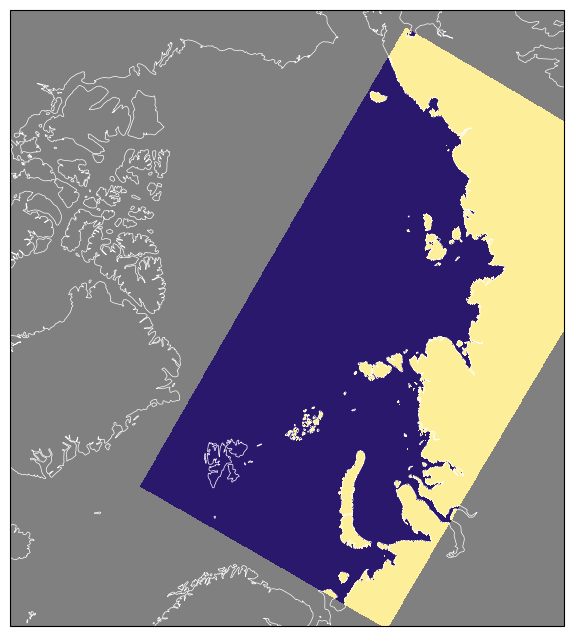

In [45]:
show_mask = True

if show_mask:

    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    lat_ctr, lon_ctr = 86, 30

    cart_proj = ccrs.Stereographic(
        central_latitude=lat_ctr,
        central_longitude=lon_ctr,
        scale_factor=None, globe=None)

    fig = plt.figure(figsize = (8, 8))
    ax = plt.axes(projection=cart_proj)

    ax.set_facecolor('gray')
    # Coastline
    ax.coastlines('50m', color = 'w', lw = 0.5 )

    # Land
    land_50m = cfeature.NaturalEarthFeature(
        'physical', 'land', '50m',
        edgecolor='k', linewidth = 1,
        facecolor=cfeature.COLORS['land'])

   # ax.add_feature(land_50m)

    # Set boundaries
    ax.set_extent([-20, 191, 66, 89.5], crs=ccrs.PlateCarree())
    
    # Transform mask coordiates (x-y) to (lat-lon) 
  #  wgs84_proj = pyproj.CRS("EPSG:4326") # latlon with WGS84 datum
  #  MASK_to_latlon = pyproj.Transformer.from_crs(MASK.proj.data.item(), wgs84_proj)
  #  mask_lon, mask_lat = None, None

    ax.pcolormesh(MASK.x, MASK.y, MASK.is_land, 
                  cmap = cmocean.cm.haline, transform = ccrs.epsg(3996))
    